# PCA Workflow for Procrustes-Aligned M2 Coordinate Data

This notebook performs Principal Component Analysis (PCA) on Procrustes-aligned mandibular second molar coordinate data.

It is designed as a repository-ready, viewer-friendly version of the PCA workflow. The goal is to make the analysis easy to run from the GitHub repository with minimal editing.

## What this notebook does

1. Loads a CSV file containing specimen metadata and Procrustes-aligned coordinates.
2. Detects coordinate columns named `X1`, `Y1`, `X2`, `Y2`, ..., `X23`, `Y23`.
3. Performs PCA on the coordinate variables.
4. Saves PCA scores, PCA loadings, and explained variance summaries.
5. Creates and saves PCA plots.

## Important note

This notebook assumes that Generalized Procrustes Analysis has already been performed. It does **not** perform GPA.


## 1. Edit file paths and analysis settings

Update `INPUT_FILE` if your data file is stored somewhere else.

For the manuscript repository example data, make sure GPA has been run, and the following output file containing the csv file titled "procrustes_aligned_coordinates.csv" exists within path     ("../../results/gpa/procrustes_aligned_coordinates.csv"). 

In [ ]:
# -----------------------------
# Editable settings
# -----------------------------

from pathlib import Path

#INPUT_FILE = Path("../../results/gpa/procrustes_aligned_coordinates.csv") # <- Change this to the path that holds the coordinate file for which you would like to run PCA
INPUT_FILE = Path("INSERT FILE PATH TO PROCRUSTES ALIGNED COORDINATES HERE")
# Folder where PCA outputs will be saved.
OUTPUT_DIR = Path("../../results/pca")

# If your dietary category column has a different name, replace None with the column name.
# Example: DIET_COLUMN = "Diet"
# In the manuscript dataset, "Column1" contains dietary category information.
DIET_COLUMN = None

# Metadata columns to keep in the PCA scores output if present.
METADATA_COLUMNS = ["Species", "Column1", "Tribe", "File_Name"]

# Number of principal components to calculate.
# None calculates all possible components.
N_COMPONENTS = None

# Cumulative variance threshold to report.
VARIANCE_THRESHOLD = 0.95

# Number of standard deviations used for PC shape model plots.
SHAPE_SD = 2.0

# Set to True to skip plot generation.
NO_PLOTS = False

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input file: {INPUT_FILE}")
print(f"Output folder: {OUTPUT_DIR}")


Input file: /Users/rebeccaharbert/Desktop/Dissertation/GM_M2_Metaconid_Analysis_2/results/gpa/procrustes_aligned_coordinates.csv
Output folder: ../../results/pca


## 2. Import packages and define helper functions

In [5]:
# -----------------------------
# Imports and helper functions
# -----------------------------

from __future__ import annotations

import re
from typing import Iterable, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial import ConvexHull, QhullError
from sklearn.decomposition import PCA


def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    """
    Clean column names by removing whitespace and invisible spacing characters.

    This makes the notebook more tolerant of CSV files exported from spreadsheets.
    """
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.replace(r"\s+", "", regex=True)
        .str.replace("\ufeff", "", regex=False)
    )
    return df


def coordinate_sort_key(column_name: str) -> tuple[int, int]:
    """
    Sort coordinate columns in anatomical order:
    X1, Y1, X2, Y2, ..., X23, Y23.
    """
    match = re.fullmatch(r"([XY])(\d+)", column_name)
    if match is None:
        return (10_000, 10_000)

    axis, number = match.groups()
    axis_order = 0 if axis == "X" else 1
    return (int(number), axis_order)


def find_coordinate_columns(df: pd.DataFrame) -> List[str]:
    """
    Detect coordinate columns named X1, Y1, X2, Y2, etc.
    """
    coordinate_columns = [
        col for col in df.columns
        if re.fullmatch(r"[XY]\d+", str(col))
    ]

    coordinate_columns = sorted(coordinate_columns, key=coordinate_sort_key)

    if len(coordinate_columns) == 0:
        raise ValueError(
            "No coordinate columns were found. Expected columns named like "
            "X1, Y1, X2, Y2, ..., X23, Y23."
        )

    if len(coordinate_columns) % 2 != 0:
        raise ValueError(
            f"Found {len(coordinate_columns)} coordinate columns, which is not even. "
            "Each landmark should have both an X and a Y coordinate."
        )

    expected_numbers = sorted(
        {int(re.fullmatch(r"[XY](\d+)", c).group(1)) for c in coordinate_columns}
    )
    missing_pairs = []
    for n in expected_numbers:
        if f"X{n}" not in coordinate_columns or f"Y{n}" not in coordinate_columns:
            missing_pairs.append(n)

    if missing_pairs:
        raise ValueError(
            "Some landmarks are missing either X or Y coordinates: "
            + ", ".join(map(str, missing_pairs))
        )

    return coordinate_columns


def resolve_diet_column(df: pd.DataFrame, requested: Optional[str]) -> Optional[str]:
    """
    Identify the column containing dietary categories.
    """
    if requested is not None:
        if requested not in df.columns:
            raise ValueError(
                f"The requested diet column '{requested}' was not found. "
                f"Available columns are: {list(df.columns)}"
            )
        return requested

    possible_names = [
        "Diet",
        "diet",
        "DietCategory",
        "Diet_Category",
        "DietaryCategory",
        "Dietary_Category",
        "Column1",
    ]

    for name in possible_names:
        if name in df.columns:
            return name

    return None


def ensure_numeric_coordinates(df: pd.DataFrame, coordinate_columns: Iterable[str]) -> pd.DataFrame:
    """
    Convert coordinate columns to numeric values and fail clearly if conversion fails.
    """
    coords = df[list(coordinate_columns)].copy()

    for col in coords.columns:
        coords[col] = pd.to_numeric(coords[col], errors="coerce")

    missing_counts = coords.isna().sum()
    problematic = missing_counts[missing_counts > 0]

    if not problematic.empty:
        raise ValueError(
            "Some coordinate columns contain missing or non-numeric values after conversion:\n"
            + problematic.to_string()
            + "\nPlease check the input CSV."
        )

    return coords


def percent_label(explained_variance_ratio: np.ndarray, pc_index: int) -> str:
    """
    Return a formatted percent variance label for a principal component.
    """
    return f"{explained_variance_ratio[pc_index] * 100:.1f}%"


## 3. Define plotting functions

In [7]:
# -----------------------------
# Plotting helper functions
# -----------------------------

def make_scree_plot(
    explained_variance_ratio: np.ndarray,
    cumulative_explained_variance: np.ndarray,
    output_path: Path,
    variance_threshold: float,
) -> None:
    """
    Save a scree plot.
    """
    pc_numbers = np.arange(1, len(explained_variance_ratio) + 1)

    plt.figure(figsize=(9, 6))
    plt.plot(pc_numbers, explained_variance_ratio, marker="o", linewidth=2, label="Individual variance")
    plt.plot(pc_numbers, cumulative_explained_variance, marker="s", linewidth=2, label="Cumulative variance")
    plt.axhline(variance_threshold, linestyle="--", linewidth=1, label=f"{variance_threshold:.0%} threshold")
    plt.title("PCA Scree Plot")
    plt.xlabel("Principal Component")
    plt.ylabel("Proportion of Variance Explained")
    plt.xticks(pc_numbers)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()
    print(f"Saved: {output_path}")

def make_pca_scatter(
    pca_df: pd.DataFrame,
    color_column: str,
    explained_variance_ratio: np.ndarray,
    output_path: Path,
    title: str,
    add_hulls: bool = False,
    legend_title=None,
    legend_position="bottom",
    
) -> None:
    """
    Save PC1 vs PC2 scatter plot, optionally with convex hulls.
    """
    if color_column not in pca_df.columns:
        print(f"Skipping plot because '{color_column}' column was not found.")
        return

    if "PC1" not in pca_df.columns or "PC2" not in pca_df.columns:
        print("Skipping PC1/PC2 plot because fewer than two PCs were calculated.")
        return

    plt.figure(figsize=(10, 7))

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue=color_column,
        s=70,
        edgecolor="black",
        linewidth=0.3,
    )

    if add_hulls:
        categories = pca_df[color_column].dropna().unique()
        palette = dict(zip(categories, sns.color_palette(n_colors=len(categories))))

        for category in categories:
            points = pca_df.loc[
                pca_df[color_column] == category, ["PC1", "PC2"]
            ].dropna().values

            if len(points) >= 3:
                try:
                    hull = ConvexHull(points)
                    hull_points = points[hull.vertices]
                    plt.fill(
                        hull_points[:, 0],
                        hull_points[:, 1],
                        alpha=0.20,
                        color=palette[category],
                    )
                except QhullError:
                    print(f"Skipping convex hull for '{category}' because points are collinear.")

    plt.title(title)
    plt.xlabel(f"PC1 ({percent_label(explained_variance_ratio, 0)} variance)")
    plt.ylabel(f"PC2 ({percent_label(explained_variance_ratio, 1)} variance)")

    # Place the legend below the plot
    legend_label = legend_title if legend_title is not None else color_column

    if legend_position == "right":
        plt.legend(
            title=legend_label,
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            borderaxespad=0,
            frameon=True,
        )

    elif legend_position == "inside":
        plt.legend(
            title=legend_label,
            loc="best",
            frameon=True,
        )

    else:
        plt.legend(
            title=legend_label,
            bbox_to_anchor=(0.5, -0.2),
            loc="upper center",
            ncol=4,
            frameon=True,
        )
    plt.tight_layout(rect=[0, 0.1, 1, 1])
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_path}")


def make_loading_heatmap(
    loading_df: pd.DataFrame,
    output_path: Path,
    n_pcs: int = 2,
) -> None:
    """
    Save a heatmap of PCA loadings for the first n PCs.
    """
    n_pcs = min(n_pcs, loading_df.shape[1])

    plt.figure(figsize=(10, max(8, 0.25 * loading_df.shape[0])))
    sns.heatmap(
        loading_df.iloc[:, :n_pcs],
        cmap="coolwarm",
        center=0,
        annot=False,
    )
    plt.title(f"PCA Loadings Heatmap: First {n_pcs} PCs")
    plt.xlabel("Principal Component")
    plt.ylabel("Coordinate")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()
    print(f"Saved: {output_path}")


def plot_shape(ax, shape: np.ndarray, title: str) -> None:
    """
    Plot a single landmark shape.
    """
    x_coords = shape[0::2]
    y_coords = shape[1::2]

    x_closed = np.append(x_coords, x_coords[0])
    y_closed = np.append(y_coords, y_coords[0])

    ax.plot(x_closed, y_closed, marker="o", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.axis("equal")


def make_shape_model_plot(
    coords_df: pd.DataFrame,
    pca: PCA,
    output_path: Path,
    shape_sd: float,
) -> None:
    """
    Save shape models for PC1 and PC2.

    This shows mean shape plus/minus a chosen number of standard deviations
    along PC1 and PC2.
    """
    if pca.n_components_ < 2:
        print("Skipping shape model plot because fewer than two PCs were calculated.")
        return

    mean_shape = coords_df.mean(axis=0).values
    pc1_vector = pca.components_[0]
    pc2_vector = pca.components_[1]

    pc1_scale = shape_sd * np.sqrt(pca.explained_variance_[0])
    pc2_scale = shape_sd * np.sqrt(pca.explained_variance_[1])

    shape_model_pc1_plus = mean_shape + pc1_scale * pc1_vector
    shape_model_pc1_minus = mean_shape - pc1_scale * pc1_vector
    shape_model_pc2_plus = mean_shape + pc2_scale * pc2_vector
    shape_model_pc2_minus = mean_shape - pc2_scale * pc2_vector

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    plot_shape(axes[0, 0], shape_model_pc1_plus, f"PC1 + {shape_sd:g} SD")
    plot_shape(axes[0, 1], shape_model_pc1_minus, f"PC1 - {shape_sd:g} SD")
    plot_shape(axes[1, 0], shape_model_pc2_plus, f"PC2 + {shape_sd:g} SD")
    plot_shape(axes[1, 1], shape_model_pc2_minus, f"PC2 - {shape_sd:g} SD")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()
    print(f"Saved: {output_path}")




In [8]:
def plot_shape(ax, shape: np.ndarray, title: str) -> None:
    """
    Plot an open M2 landmark contour.
    """
    landmarks = np.asarray(shape).reshape(-1, 2)

    x_coords = landmarks[:, 0]
    y_coords = landmarks[:, 1]

    ax.plot(
        x_coords,
        y_coords,
        marker="o",
        markersize=4,
        linewidth=1.5
    )

    ax.set_title(title)
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.set_aspect("equal", adjustable="box")

## 4. Load and validate the input data

This cell checks that the input file exists, detects coordinate columns, converts coordinate values to numeric values, and identifies metadata columns.

In [10]:
# -----------------------------
# Load and validate the input data
# -----------------------------

#if not INPUT_FILE.exists():
#    raise FileNotFoundError(
#        f"Input file not found: {INPUT_FILE}\n\n"
#        "Check that the path in the editable settings cell is correct. "
#        "If you are running this notebook from a different folder, update INPUT_FILE."
#    )

df = pd.read_csv("/Users/rebeccaharbert/Desktop/Dissertation/GM_M2_Metaconid_Analysis_2/For Plos One/results/gpa/procrustes_aligned_coordinates.csv")
df = clean_column_names(df)

print(f"Loaded {df.shape[0]} specimens and {df.shape[1]} columns.")

coordinate_columns = find_coordinate_columns(df)

print(f"Detected {len(coordinate_columns)} coordinate columns.")
print(f"This corresponds to {len(coordinate_columns) // 2} landmarks.")
print("\nFirst 10 coordinate columns:")
print(coordinate_columns[:10])

coords_df = ensure_numeric_coordinates(df, coordinate_columns)

metadata_columns = [col for col in METADATA_COLUMNS if col in df.columns]
missing_metadata = [col for col in METADATA_COLUMNS if col not in df.columns]

if missing_metadata:
    print(
        "\nWarning: These requested metadata columns were not found and will be skipped: "
        + ", ".join(missing_metadata)
    )

diet_column = resolve_diet_column(df, DIET_COLUMN)

if diet_column is None:
    print(
        "\nWarning: No dietary category column was detected. "
        "Diet-colored PCA plots will be skipped."
    )
else:
    print(f"\nDiet column used for diet plots: {diet_column}")
    if diet_column not in metadata_columns:
        metadata_columns.append(diet_column)

print("\nMetadata columns retained:")
print(metadata_columns)


Loaded 132 specimens and 62 columns.
Detected 46 coordinate columns.
This corresponds to 23 landmarks.

First 10 coordinate columns:
['X1', 'Y1', 'X2', 'Y2', 'X3', 'Y3', 'X4', 'Y4', 'X5', 'Y5']

Diet column used for diet plots: Column1

Metadata columns retained:
['Species', 'Column1', 'Tribe', 'File_Name']


In [ ]:
# ============================================================
# LOAD GPA COORDINATES FOR PCA
# ============================================================

import pandas as pd
import numpy as np

# Always read directly from the current GPA output
df = pd.read_csv(INPUT_FILE)
df = clean_column_names(df)

# Explicit landmark coordinate order
coordinate_columns = [
    f"{axis}{i}"
    for i in range(1, 24)
    for axis in ("X", "Y")
]

# Rebuild PCA coordinate matrix from the current file
coords_df = ensure_numeric_coordinates(df, coordinate_columns)

# Verify that no coordinates have been modified
raw_coords = df[coordinate_columns].to_numpy(dtype=float)
processed_coords = coords_df.to_numpy(dtype=float)

difference = np.max(
    np.abs(raw_coords - processed_coords)
)

print("GPA input:", INPUT_FILE.resolve())
print("Number of specimens:", len(coords_df))
print("Number of landmarks:", len(coordinate_columns) // 2)
print("Maximum difference:", difference)

assert np.allclose(raw_coords, processed_coords), (
    "ERROR: PCA coordinates do not match the GPA CSV!"
)

print("PASS: PCA is using the original GPA coordinates.")

# Restore metadata handling used by downstream cells
metadata_columns = [
    col for col in METADATA_COLUMNS if col in df.columns
]

diet_column = resolve_diet_column(df, DIET_COLUMN)

if diet_column is not None and diet_column not in metadata_columns:
    metadata_columns.append(diet_column)

## 5. Run PCA

PCA is performed on all detected coordinate columns. Metadata columns are retained only for labeling and plotting.

In [31]:
# -----------------------------
# Run PCA
# -----------------------------

max_components = min(coords_df.shape[0], coords_df.shape[1])
n_components = N_COMPONENTS if N_COMPONENTS is not None else max_components

if n_components < 1 or n_components > max_components:
    raise ValueError(
        f"N_COMPONENTS must be between 1 and {max_components}. "
        f"Received: {n_components}"
    )

pca = PCA(n_components=n_components)
principal_components = pca.fit_transform(coords_df)

pc_columns = [f"PC{i + 1}" for i in range(principal_components.shape[1])]
pc_scores = pd.DataFrame(principal_components, columns=pc_columns)

pca_df = pd.concat(
    [df[metadata_columns].reset_index(drop=True), pc_scores.reset_index(drop=True)],
    axis=1,
)

explained_variance_ratio = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

n_components_threshold = int(np.argmax(cumulative_explained_variance >= VARIANCE_THRESHOLD) + 1)

explained_variance_df = pd.DataFrame({
    "PC": pc_columns,
    "explained_variance": pca.explained_variance_,
    "explained_variance_ratio": explained_variance_ratio,
    "explained_variance_percent": explained_variance_ratio * 100,
    "cumulative_explained_variance_ratio": cumulative_explained_variance,
    "cumulative_explained_variance_percent": cumulative_explained_variance * 100,
})

loading_df = pd.DataFrame(
    pca.components_.T,
    columns=pc_columns,
    index=coordinate_columns,
)
loading_df.index.name = "coordinate"

print("PCA complete.")
print(f"PC1 explains {percent_label(explained_variance_ratio, 0)} of variance.")

if len(explained_variance_ratio) > 1:
    print(f"PC2 explains {percent_label(explained_variance_ratio, 1)} of variance.")

print(
    f"{n_components_threshold} PCs are needed to explain "
    f"at least {VARIANCE_THRESHOLD:.0%} of total variance."
)

display(explained_variance_df.head(10))
display(pca_df.head())


PCA complete.
PC1 explains 59.3% of variance.
PC2 explains 25.9% of variance.
6 PCs are needed to explain at least 95% of total variance.


,PC,explained_variance,explained_variance_ratio,explained_variance_percent,cumulative_explained_variance_ratio,cumulative_explained_variance_percent
0,PC1,0.008302,0.593059,59.305911,0.593059,59.305911
1,PC2,0.003626,0.259045,25.904535,0.852104,85.210446
2,PC3,0.000708,0.050569,5.056943,0.902674,90.267389
3,PC4,0.000367,0.026182,2.618168,0.928856,92.885557
4,PC5,0.000258,0.018420,1.842020,0.947276,94.727577
5,PC6,0.000135,0.009617,0.961728,0.956893,95.689305
6,PC7,0.000091,0.006523,0.652344,0.963416,96.341649
7,PC8,0.000079,0.005613,0.561273,0.969029,96.902922
8,PC9,0.000067,0.004782,0.478235,0.973812,97.381157
9,PC10,0.000055,0.003920,0.392034,0.977732,97.773190


,Species,Column1,Tribe,File_Name,PC1,PC2,PC3,PC4,PC5,PC6,...,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46
0,Alcelaphus buselaphus,grazer,Alcelaphini,A_buselaphus_27999_lower_lingual_molars,0.087257,0.031392,-0.007282,-0.010885,0.020831,-0.008755,...,-0.000245,-0.000914,-0.001282,0.000563,0.000823,-0.002035,-0.001864,8.505753e-17,2.929442e-17,5.042546e-17
1,Ammotragus lervia,grazer,Caprini,A_lervia_37874_lower_lingual_tooth row,-0.082484,0.061925,0.084800,-0.093869,-0.030227,-0.022695,...,0.000588,0.000763,-0.000886,0.000657,-0.000570,-0.000294,-0.000578,9.310755e-17,-5.500570e-17,-2.492739e-17
2,Aepyceros melampus,mixed feeder,Aepycerotini,A_melampus_1932.6.6.32_lower_lingual_tooth row,-0.026733,-0.026620,0.026171,0.007068,0.014575,-0.002290,...,0.000136,-0.001009,-0.003179,-0.000587,-0.002055,-0.000594,-0.000522,-6.139737e-18,5.441884e-17,-1.214696e-17
3,Aepyceros melampus,mixed feeder,Aepycerotini,A_melampus_1967.11.8.1_lower_lingual_tooth row,0.000497,0.004223,0.000882,0.013878,-0.019237,0.001905,...,0.002341,0.000271,-0.000428,-0.000440,-0.000351,-0.001368,0.000881,1.045359e-16,5.434808e-17,3.402708e-17
4,Aepyceros melampus,mixed feeder,Aepycerotini,A_melampus_1968.6.20.1_lower_lingual_tooth row,-0.023220,0.003197,-0.001242,-0.012300,-0.037650,0.002306,...,-0.000582,-0.000647,0.000349,-0.000169,0.001045,-0.001085,0.001888,-7.898550e-17,-1.386312e-17,1.545542e-17


Raw CSV vs processed PCA coordinates: 0.0
Processed PCA mean vs fitted PCA mean: 0.0


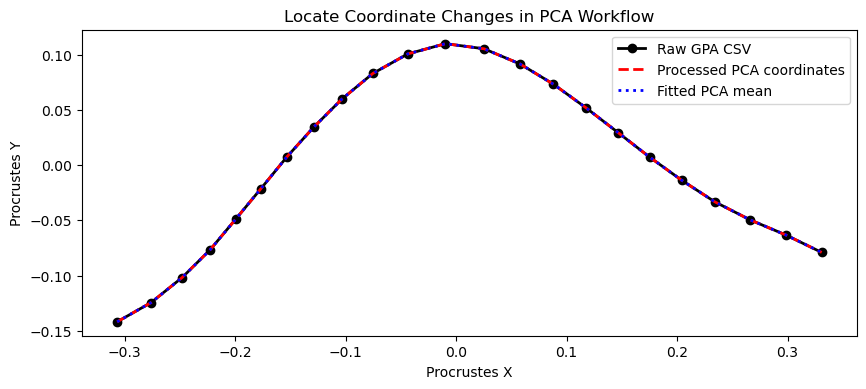

In [33]:
#### Diagnostic Check 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Read the GPA output directly from disk
raw_df = pd.read_csv(INPUT_FILE)

coord_columns = [
    f"{axis}{i}"
    for i in range(1, 24)
    for axis in ("X", "Y")
]

# Mean from raw GPA CSV
raw_mean = raw_df[coord_columns].to_numpy().mean(axis=0)

# Mean from processed PCA coordinates
processed_mean = coords_df[coord_columns].to_numpy().mean(axis=0)

# Mean stored in fitted PCA model
model_mean = pca.mean_

print(
    "Raw CSV vs processed PCA coordinates:",
    np.max(np.abs(raw_mean - processed_mean))
)

print(
    "Processed PCA mean vs fitted PCA mean:",
    np.max(np.abs(processed_mean - model_mean))
)

# Plot the three mean shapes
fig, ax = plt.subplots(figsize=(10, 6))

for shape, label, style in [
    (raw_mean, "Raw GPA CSV", "ko-"),
    (processed_mean, "Processed PCA coordinates", "r--"),
    (model_mean, "Fitted PCA mean", "b:")
]:
    landmarks = shape.reshape(23, 2)

    ax.plot(
        landmarks[:, 0],
        landmarks[:, 1],
        style,
        label=label,
        linewidth=2
    )

ax.set_title("Locate Coordinate Changes in PCA Workflow")
ax.set_xlabel("Procrustes X")
ax.set_ylabel("Procrustes Y")
ax.set_aspect("equal", adjustable="box")
ax.legend()

plt.show()

PCA mean matches loaded data: True


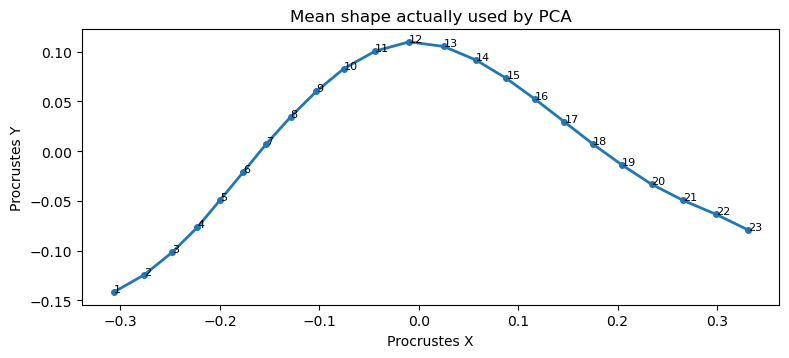

In [35]:
## Diagnostic 2 
import numpy as np
import matplotlib.pyplot as plt

# Compare the data mean and the PCA mean
data_mean = coords_df.mean(axis=0).to_numpy()
pca_mean = pca.mean_

print(
    "PCA mean matches loaded data:",
    np.allclose(data_mean, pca_mean)
)

mean_landmarks = pca_mean.reshape(-1, 2)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mean_landmarks[:, 0],
    mean_landmarks[:, 1],
    "-o",
    linewidth=2,
    markersize=4
)

for i, (x, y) in enumerate(mean_landmarks, start=1):
    ax.annotate(str(i), (x, y), fontsize=8)

ax.set_title("Mean shape actually used by PCA")
ax.set_xlabel("Procrustes X")
ax.set_ylabel("Procrustes Y")
ax.set_aspect("equal", adjustable="box")

plt.show()

GPA mean shape dimensions: (23, 2)
PCA mean shape dimensions: (23, 2)
Maximum coordinate difference: 0.002323027514697096


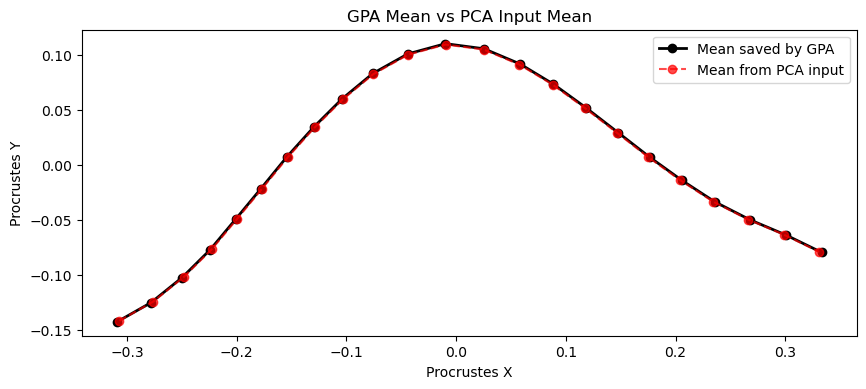

In [37]:
## Diagnostic III 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the actual GPA file loaded by PCA
gpa_dir = INPUT_FILE.parent

# Load the mean shape saved by GPA
saved_mean = pd.read_csv(
    gpa_dir / "gpa_mean_shape.csv"
)

# Mean calculated from the PCA input
pca_mean = coords_df.mean(axis=0).to_numpy().reshape(-1, 2)

# Mean saved directly by GPA
gpa_mean = saved_mean[["X", "Y"]].to_numpy()

print("GPA mean shape dimensions:", gpa_mean.shape)
print("PCA mean shape dimensions:", pca_mean.shape)

print(
    "Maximum coordinate difference:",
    np.max(np.abs(gpa_mean - pca_mean))
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    gpa_mean[:, 0],
    gpa_mean[:, 1],
    "ko-",
    label="Mean saved by GPA",
    linewidth=2
)

ax.plot(
    pca_mean[:, 0],
    pca_mean[:, 1],
    "ro--",
    label="Mean from PCA input",
    linewidth=1.5,
    alpha=0.7
)

ax.set_title("GPA Mean vs PCA Input Mean")
ax.set_xlabel("Procrustes X")
ax.set_ylabel("Procrustes Y")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()


## 6. Save PCA output tables

In [40]:
# -----------------------------
# Save PCA output tables
# -----------------------------

pca_scores_path = OUTPUT_DIR / "pca_scores_with_metadata.csv"
explained_variance_path = OUTPUT_DIR / "pca_explained_variance.csv"
loadings_path = OUTPUT_DIR / "pca_loadings.csv"

pca_df.to_csv(pca_scores_path, index=False)
explained_variance_df.to_csv(explained_variance_path, index=False)
loading_df.to_csv(loadings_path)

print(f"Saved: {pca_scores_path}")
print(f"Saved: {explained_variance_path}")
print(f"Saved: {loadings_path}")


Saved: ../../results/pca/pca_scores_with_metadata.csv
Saved: ../../results/pca/pca_explained_variance.csv
Saved: ../../results/pca/pca_loadings.csv


## 7. Create and save PCA plots

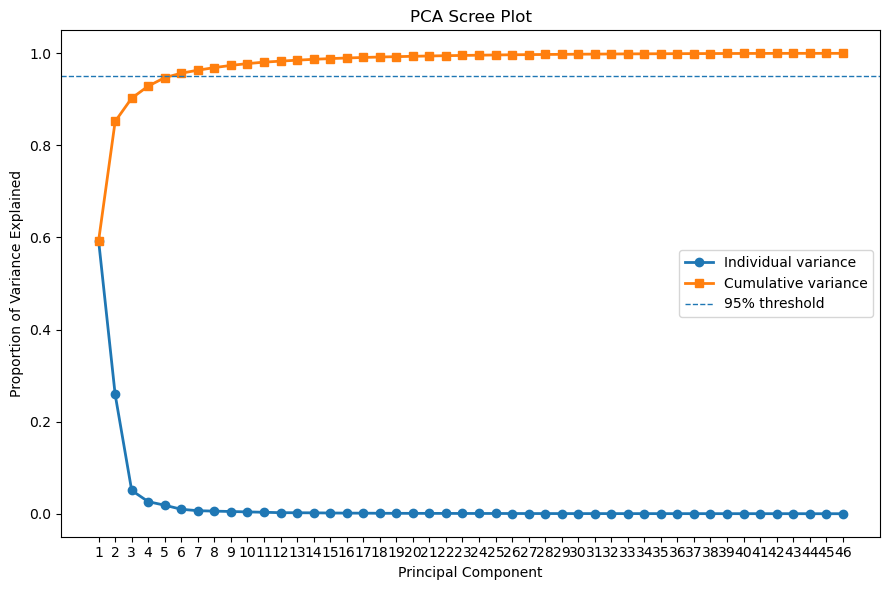

Saved: ../../results/pca/pca_scree_plot.png


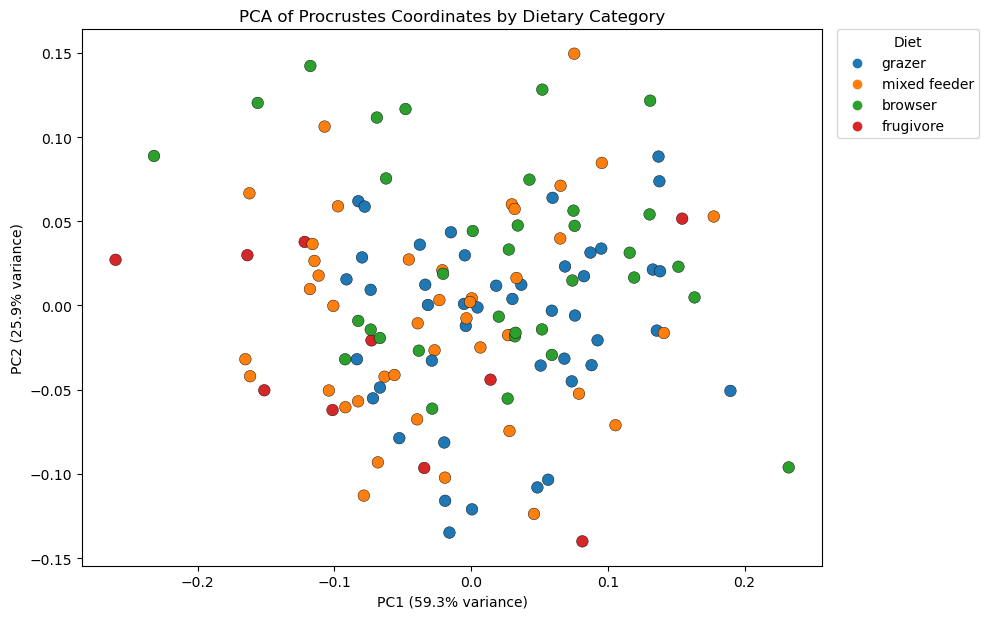

Saved: ../../results/pca/pca_PC1_PC2_by_diet.png


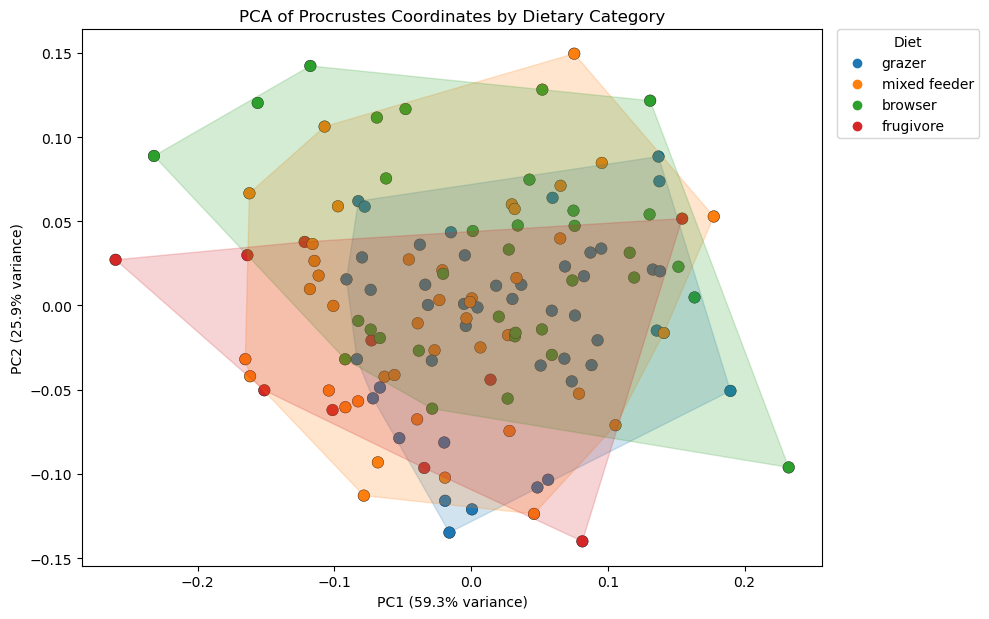

Saved: ../../results/pca/pca_PC1_PC2_by_diet_with_hulls.png


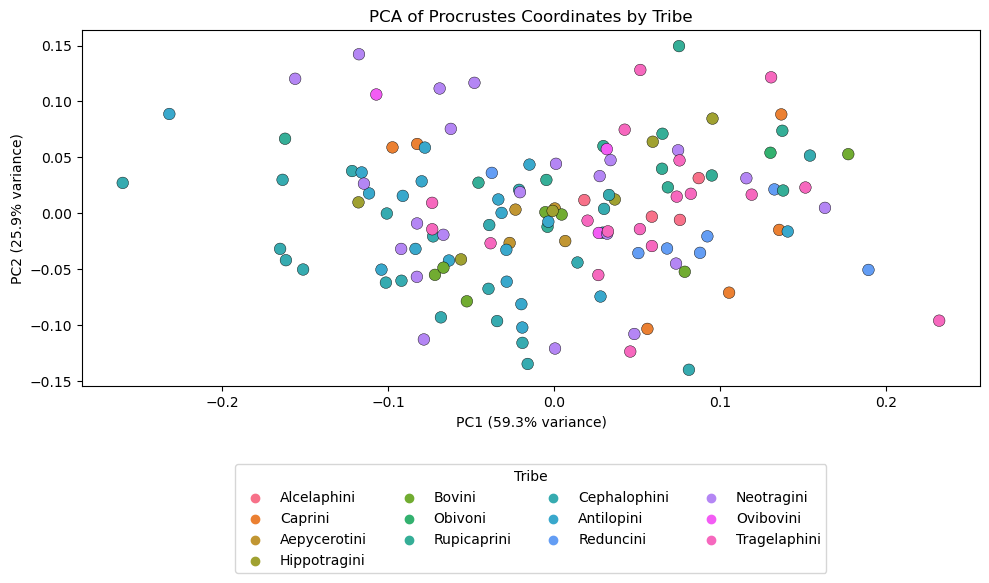

Saved: ../../results/pca/pca_PC1_PC2_by_tribe.png


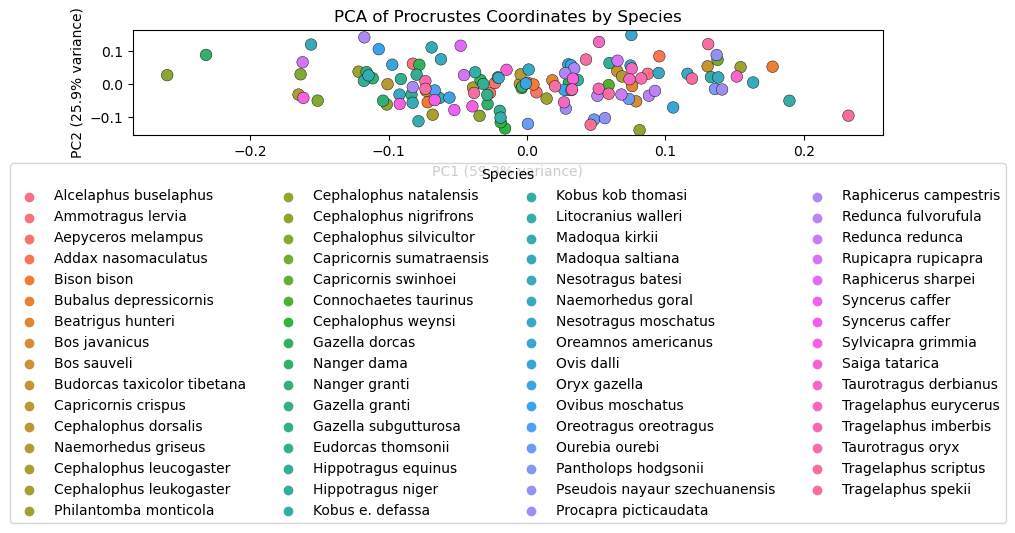

Saved: ../../results/pca/pca_PC1_PC2_by_species.png


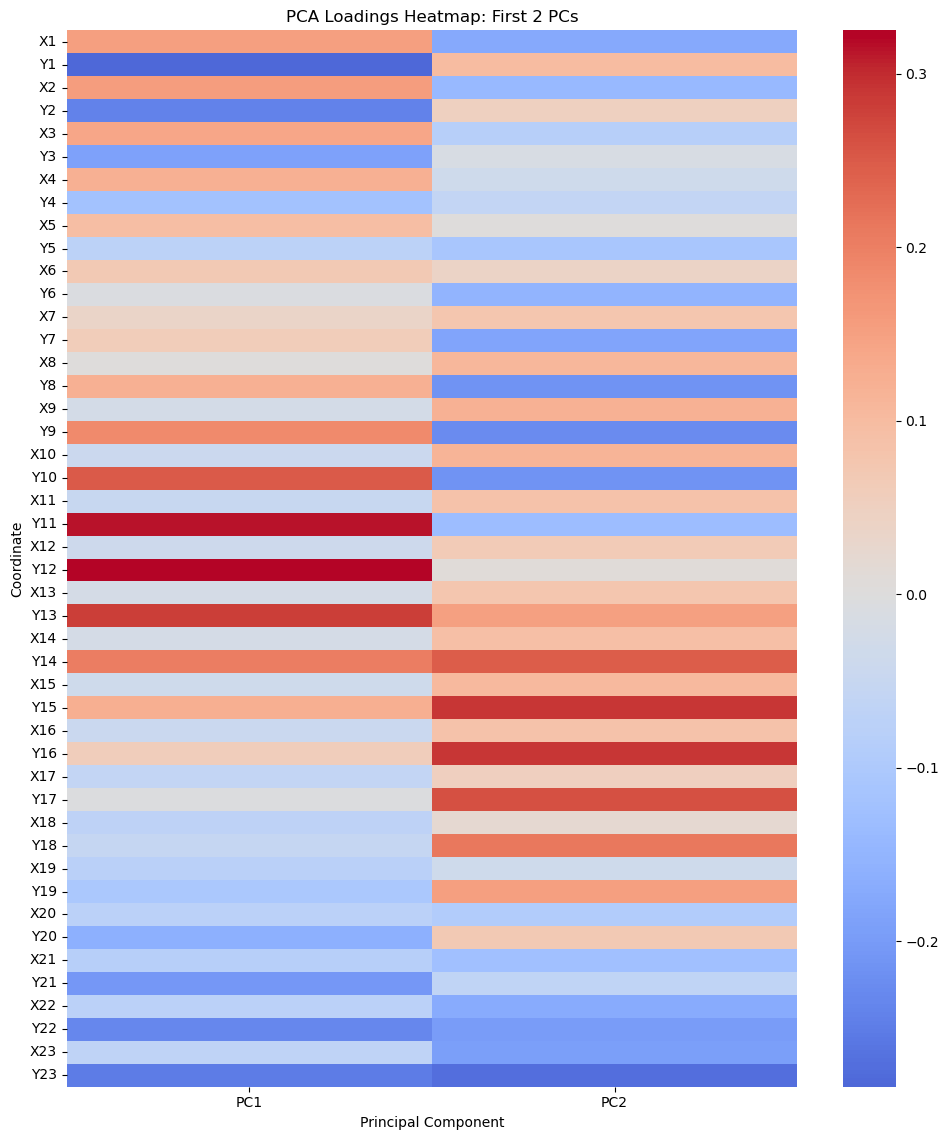

Saved: ../../results/pca/pca_loadings_heatmap_PC1_PC2.png


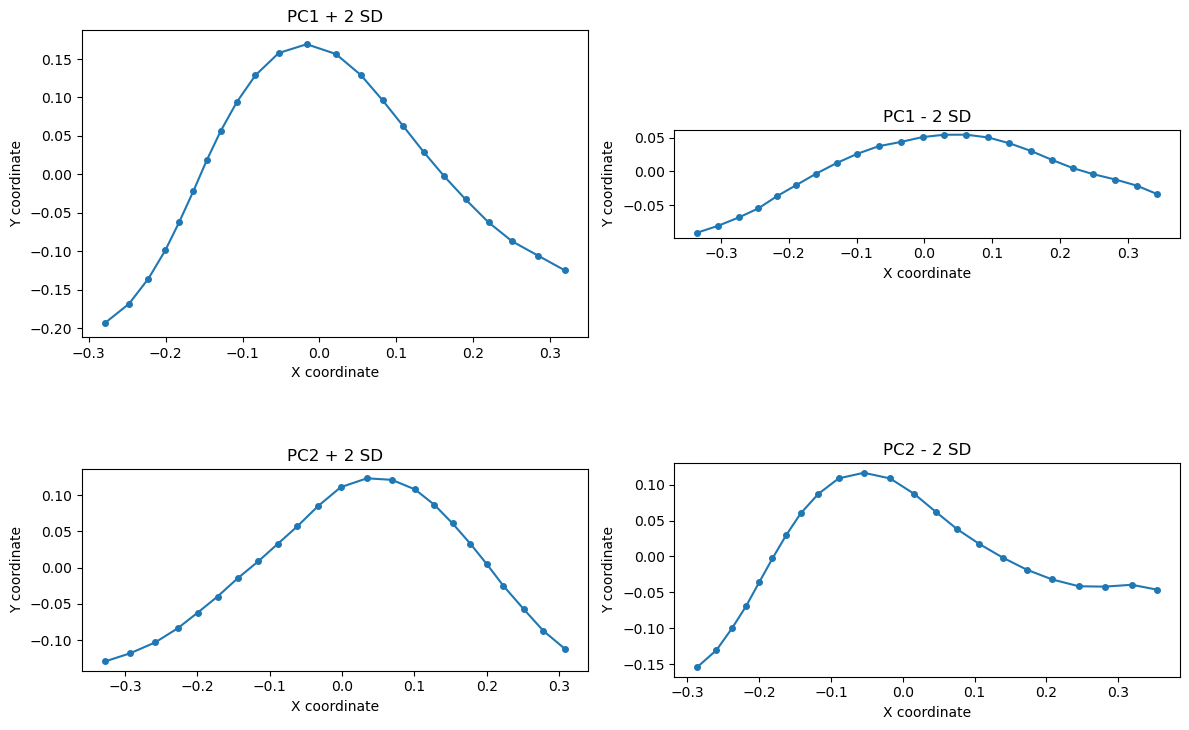

Saved: ../../results/pca/pca_shape_models_PC1_PC2.png


In [49]:
# -----------------------------
# Create and save PCA plots
# -----------------------------

if NO_PLOTS:
    print("NO_PLOTS is set to True, so plot generation was skipped.")
else:
    make_scree_plot(
        explained_variance_ratio=explained_variance_ratio,
        cumulative_explained_variance=cumulative_explained_variance,
        output_path=OUTPUT_DIR / "pca_scree_plot.png",
        variance_threshold=VARIANCE_THRESHOLD,
    )

    if diet_column is not None:
        make_pca_scatter(
            pca_df=pca_df,
            color_column=diet_column,
            explained_variance_ratio=explained_variance_ratio,
            output_path=OUTPUT_DIR / "pca_PC1_PC2_by_diet.png",
            title="PCA of Procrustes Coordinates by Dietary Category",
            add_hulls=False,
            legend_title = "Diet",
            legend_position = "right",
        )

        make_pca_scatter(
            pca_df=pca_df,
            color_column=diet_column,
            explained_variance_ratio=explained_variance_ratio,
            output_path=OUTPUT_DIR / "pca_PC1_PC2_by_diet_with_hulls.png",
            title="PCA of Procrustes Coordinates by Dietary Category",
            add_hulls=True,
            legend_title = "Diet",
            legend_position="right",
        )

    if "Tribe" in pca_df.columns:
        make_pca_scatter(
            pca_df=pca_df,
            color_column="Tribe",
            explained_variance_ratio=explained_variance_ratio,
            output_path=OUTPUT_DIR / "pca_PC1_PC2_by_tribe.png",
            title="PCA of Procrustes Coordinates by Tribe",
            add_hulls=False,
        )

    if "Species" in pca_df.columns:
        make_pca_scatter(
            pca_df=pca_df,
            color_column="Species",
            explained_variance_ratio=explained_variance_ratio,
            output_path=OUTPUT_DIR / "pca_PC1_PC2_by_species.png",
            title="PCA of Procrustes Coordinates by Species",
            add_hulls=False,
        )

    make_loading_heatmap(
        loading_df=loading_df,
        output_path=OUTPUT_DIR / "pca_loadings_heatmap_PC1_PC2.png",
        n_pcs=2,
    )

    make_shape_model_plot(
        coords_df=coords_df,
        pca=pca,
        output_path=OUTPUT_DIR / "pca_shape_models_PC1_PC2.png",
        shape_sd=SHAPE_SD,
    )


## 8. Output summary

In [ ]:
# -----------------------------
# Final output summary
# -----------------------------

print("PCA notebook workflow complete.")
print(f"\nOutputs saved to: {OUTPUT_DIR.resolve()}")
print("\nExpected output files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(f"- {path.name}")
